In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('C:/Users/Marun Yory/Desktop/Global_Climate_Energy_2022_2024_Prediction/documents/global_climate_energy_2020_2024.csv')

In [3]:
df.head()

,date,country,avg_temperature,humidity,co2_emission,energy_consumption,renewable_share,urban_population,industrial_activity_index,energy_price
0,2020-01-01,Germany,28.29,31.08,212.63,11348.75,14.42,76.39,51.22,83.93
1,2020-01-02,Germany,28.38,37.94,606.05,4166.64,5.63,86.26,78.27,110.40
2,2020-01-03,Germany,28.74,57.67,268.72,4503.80,14.20,75.92,48.96,173.58
3,2020-01-04,Germany,26.66,51.34,167.32,3259.13,13.84,63.15,97.42,89.13
4,2020-01-05,Germany,26.81,65.38,393.89,7023.72,6.93,76.02,81.89,40.60


In [4]:
df.shape

(36540, 10)

In [5]:
df.columns

Index(['date', 'country', 'avg_temperature', 'humidity', 'co2_emission',
       'energy_consumption', 'renewable_share', 'urban_population',
       'industrial_activity_index', 'energy_price'],
      dtype='str')

In [6]:
df.isnull().sum()

date                         0
country                      0
avg_temperature              0
humidity                     0
co2_emission                 0
energy_consumption           0
renewable_share              0
urban_population             0
industrial_activity_index    0
energy_price                 0
dtype: int64

In [7]:
df.nunique()

date                          1827
country                         20
avg_temperature               4481
humidity                      5987
co2_emission                 29455
energy_consumption           36035
renewable_share               2487
urban_population              3001
industrial_activity_index     5997
energy_price                 14999
dtype: int64

In [8]:
df[df.isnull().any(axis=1)]

,date,country,avg_temperature,humidity,co2_emission,energy_consumption,renewable_share,urban_population,industrial_activity_index,energy_price


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36540 entries, 0 to 36539
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   date                       36540 non-null  str    
 1   country                    36540 non-null  str    
 2   avg_temperature            36540 non-null  float64
 3   humidity                   36540 non-null  float64
 4   co2_emission               36540 non-null  float64
 5   energy_consumption         36540 non-null  float64
 6   renewable_share            36540 non-null  float64
 7   urban_population           36540 non-null  float64
 8   industrial_activity_index  36540 non-null  float64
 9   energy_price               36540 non-null  float64
dtypes: float64(8), str(2)
memory usage: 2.8 MB


In [10]:
df.describe()

,avg_temperature,humidity,co2_emission,energy_consumption,renewable_share,urban_population,industrial_activity_index,energy_price
count,36540.000000,36540.000000,36540.000000,36540.000000,36540.000000,36540.000000,36540.000000,36540.000000
mean,13.580868,59.971469,445.820452,7295.904857,15.944080,74.982156,70.173094,115.279848
std,10.077249,17.303103,234.360906,3693.928504,5.334804,8.645400,17.334816,49.178361
min,-9.600000,30.000000,50.150000,1001.890000,5.000000,60.000000,40.000000,30.000000
25%,5.630000,45.010000,248.675000,4184.177500,12.020000,67.470000,55.300000,72.420000
50%,13.790000,59.990000,422.655000,6921.620000,15.715000,75.030000,70.055000,115.240000
75%,20.840000,74.970000,628.422500,10175.110000,19.840000,82.502500,85.260000,158.270000
max,38.710000,90.000000,999.850000,15998.050000,30.870000,90.000000,100.000000,200.000000


In [11]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
numeric_cols

Index(['avg_temperature', 'humidity', 'co2_emission', 'energy_consumption',
       'renewable_share', 'urban_population', 'industrial_activity_index',
       'energy_price'],
      dtype='str')

In [12]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns
print(categorical_cols)

Index(['date', 'country'], dtype='str')


In [13]:
df['country'].value_counts()

country
Germany           1827
France            1827
Netherlands       1827
Italy             1827
Spain             1827
Sweden            1827
Norway            1827
Poland            1827
Turkey            1827
United Kingdom    1827
United States     1827
Canada            1827
Brazil            1827
India             1827
China             1827
Japan             1827
Australia         1827
South Africa      1827
Mexico            1827
Indonesia         1827
Name: count, dtype: int64

In [14]:
df['date'].value_counts()

date
2020-01-01    20
2020-01-02    20
2020-01-03    20
2020-01-04    20
2020-01-05    20
              ..
2024-12-27    20
2024-12-28    20
2024-12-29    20
2024-12-30    20
2024-12-31    20
Name: count, Length: 1827, dtype: int64

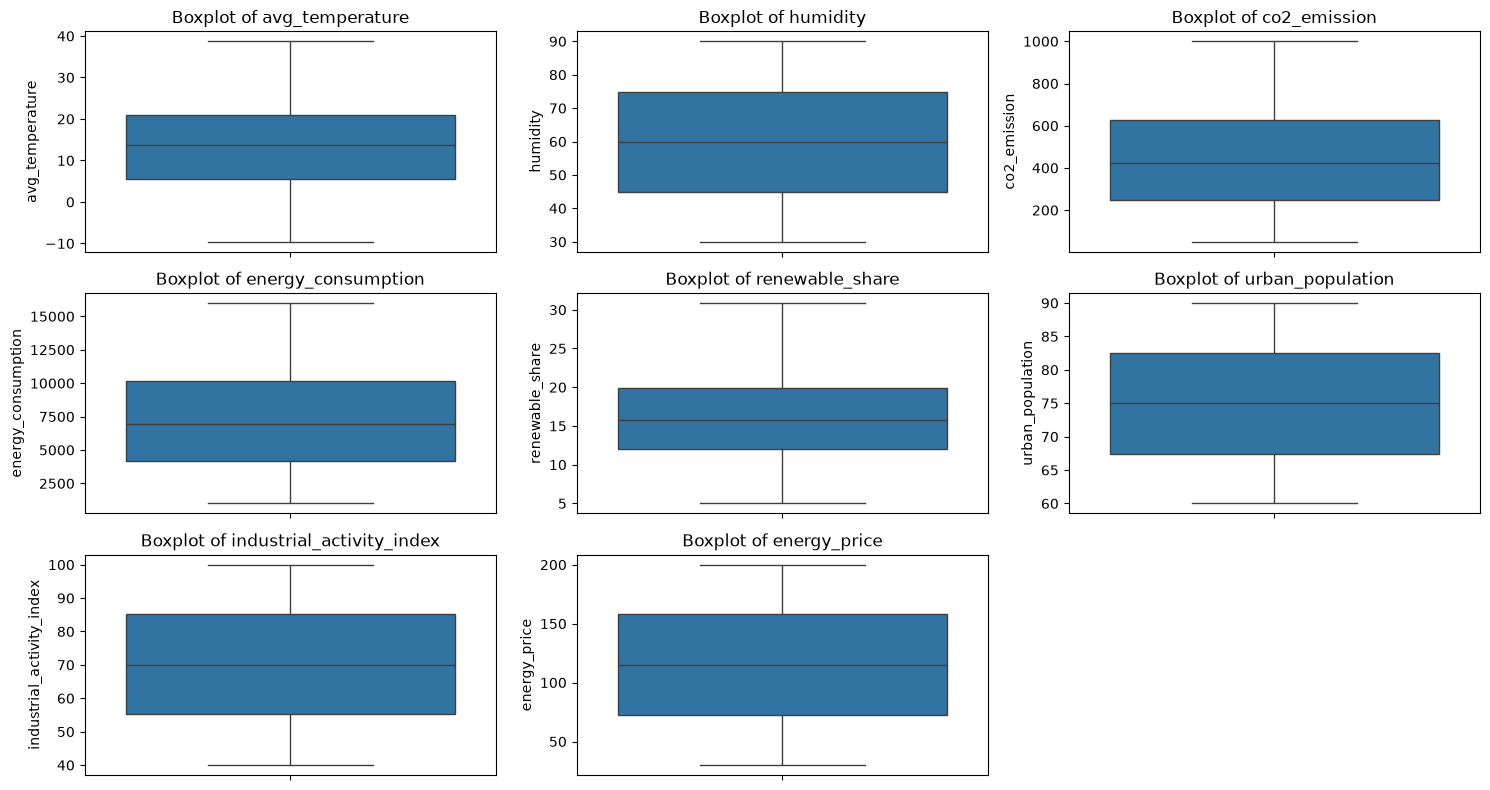

In [15]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df, y=col)
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

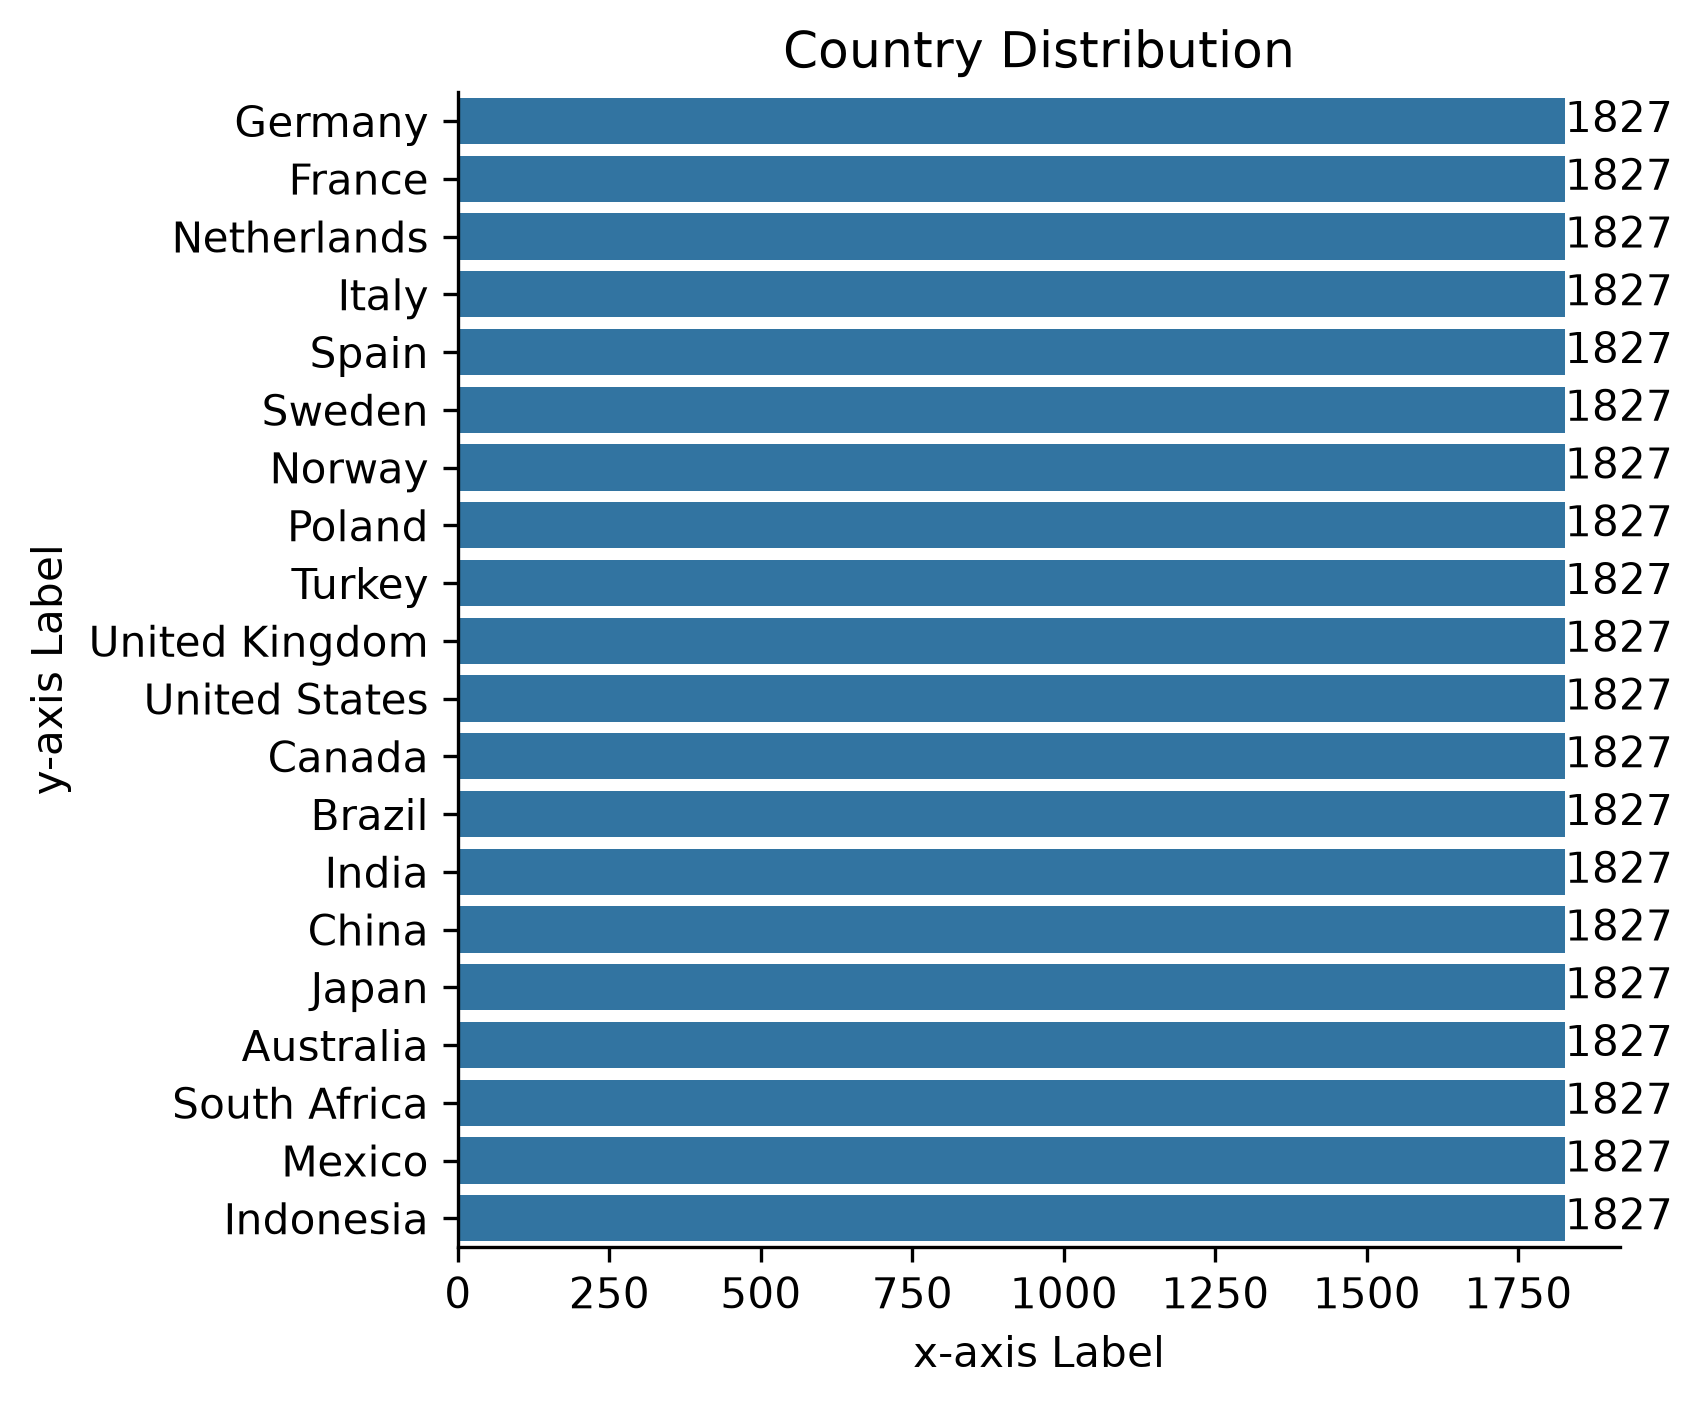

In [16]:
fig, ax  = plt.subplots(figsize = (5, 5), dpi = 300)
sns.barplot(y = df['country'].value_counts().index,
            x = df['country'].value_counts(),
           width= 0.8)

ax.set_title('Country Distribution')
ax.set_ylabel('y-axis Label')
ax.set_xlabel('x-axis Label')
ax.bar_label(ax.containers[0]) # Data label
sns.despine();

In [17]:
correlation_matrix = df[numeric_cols].corr()

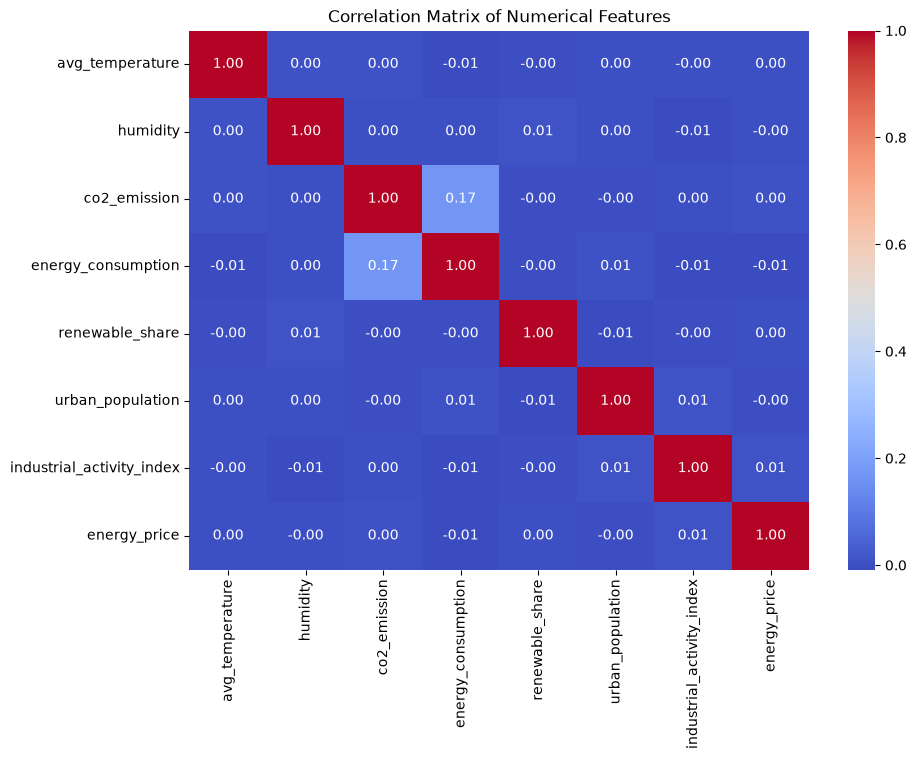

In [18]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

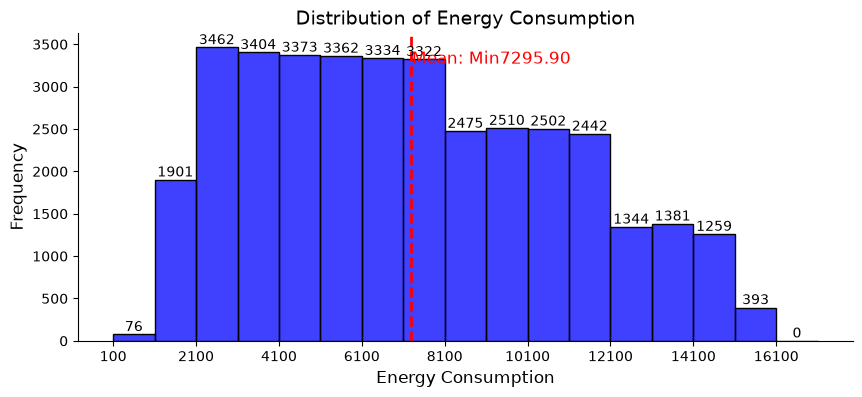

In [19]:
mean_energy = df['energy_consumption'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df['energy_consumption'], bins=np.arange(100, 18000, 1000), ax = ax, color = 'b')

ax.set_xticks(np.arange(100,18000, 2000))
ax.bar_label(ax.containers[0])

ax.set_xlabel('Energy Consumption', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Distribution of Energy Consumption', fontsize=14)

# Add vertical line for mean
ax.axvline(df['energy_consumption'].mean(), color='r', linestyle='--', linewidth=2)
ax.text(mean_energy+10 , ax.get_ylim()[1] * 0.9, f'Mean: Min{mean_energy:.2f}', color='r', fontsize=12)
sns.despine()
plt.show()

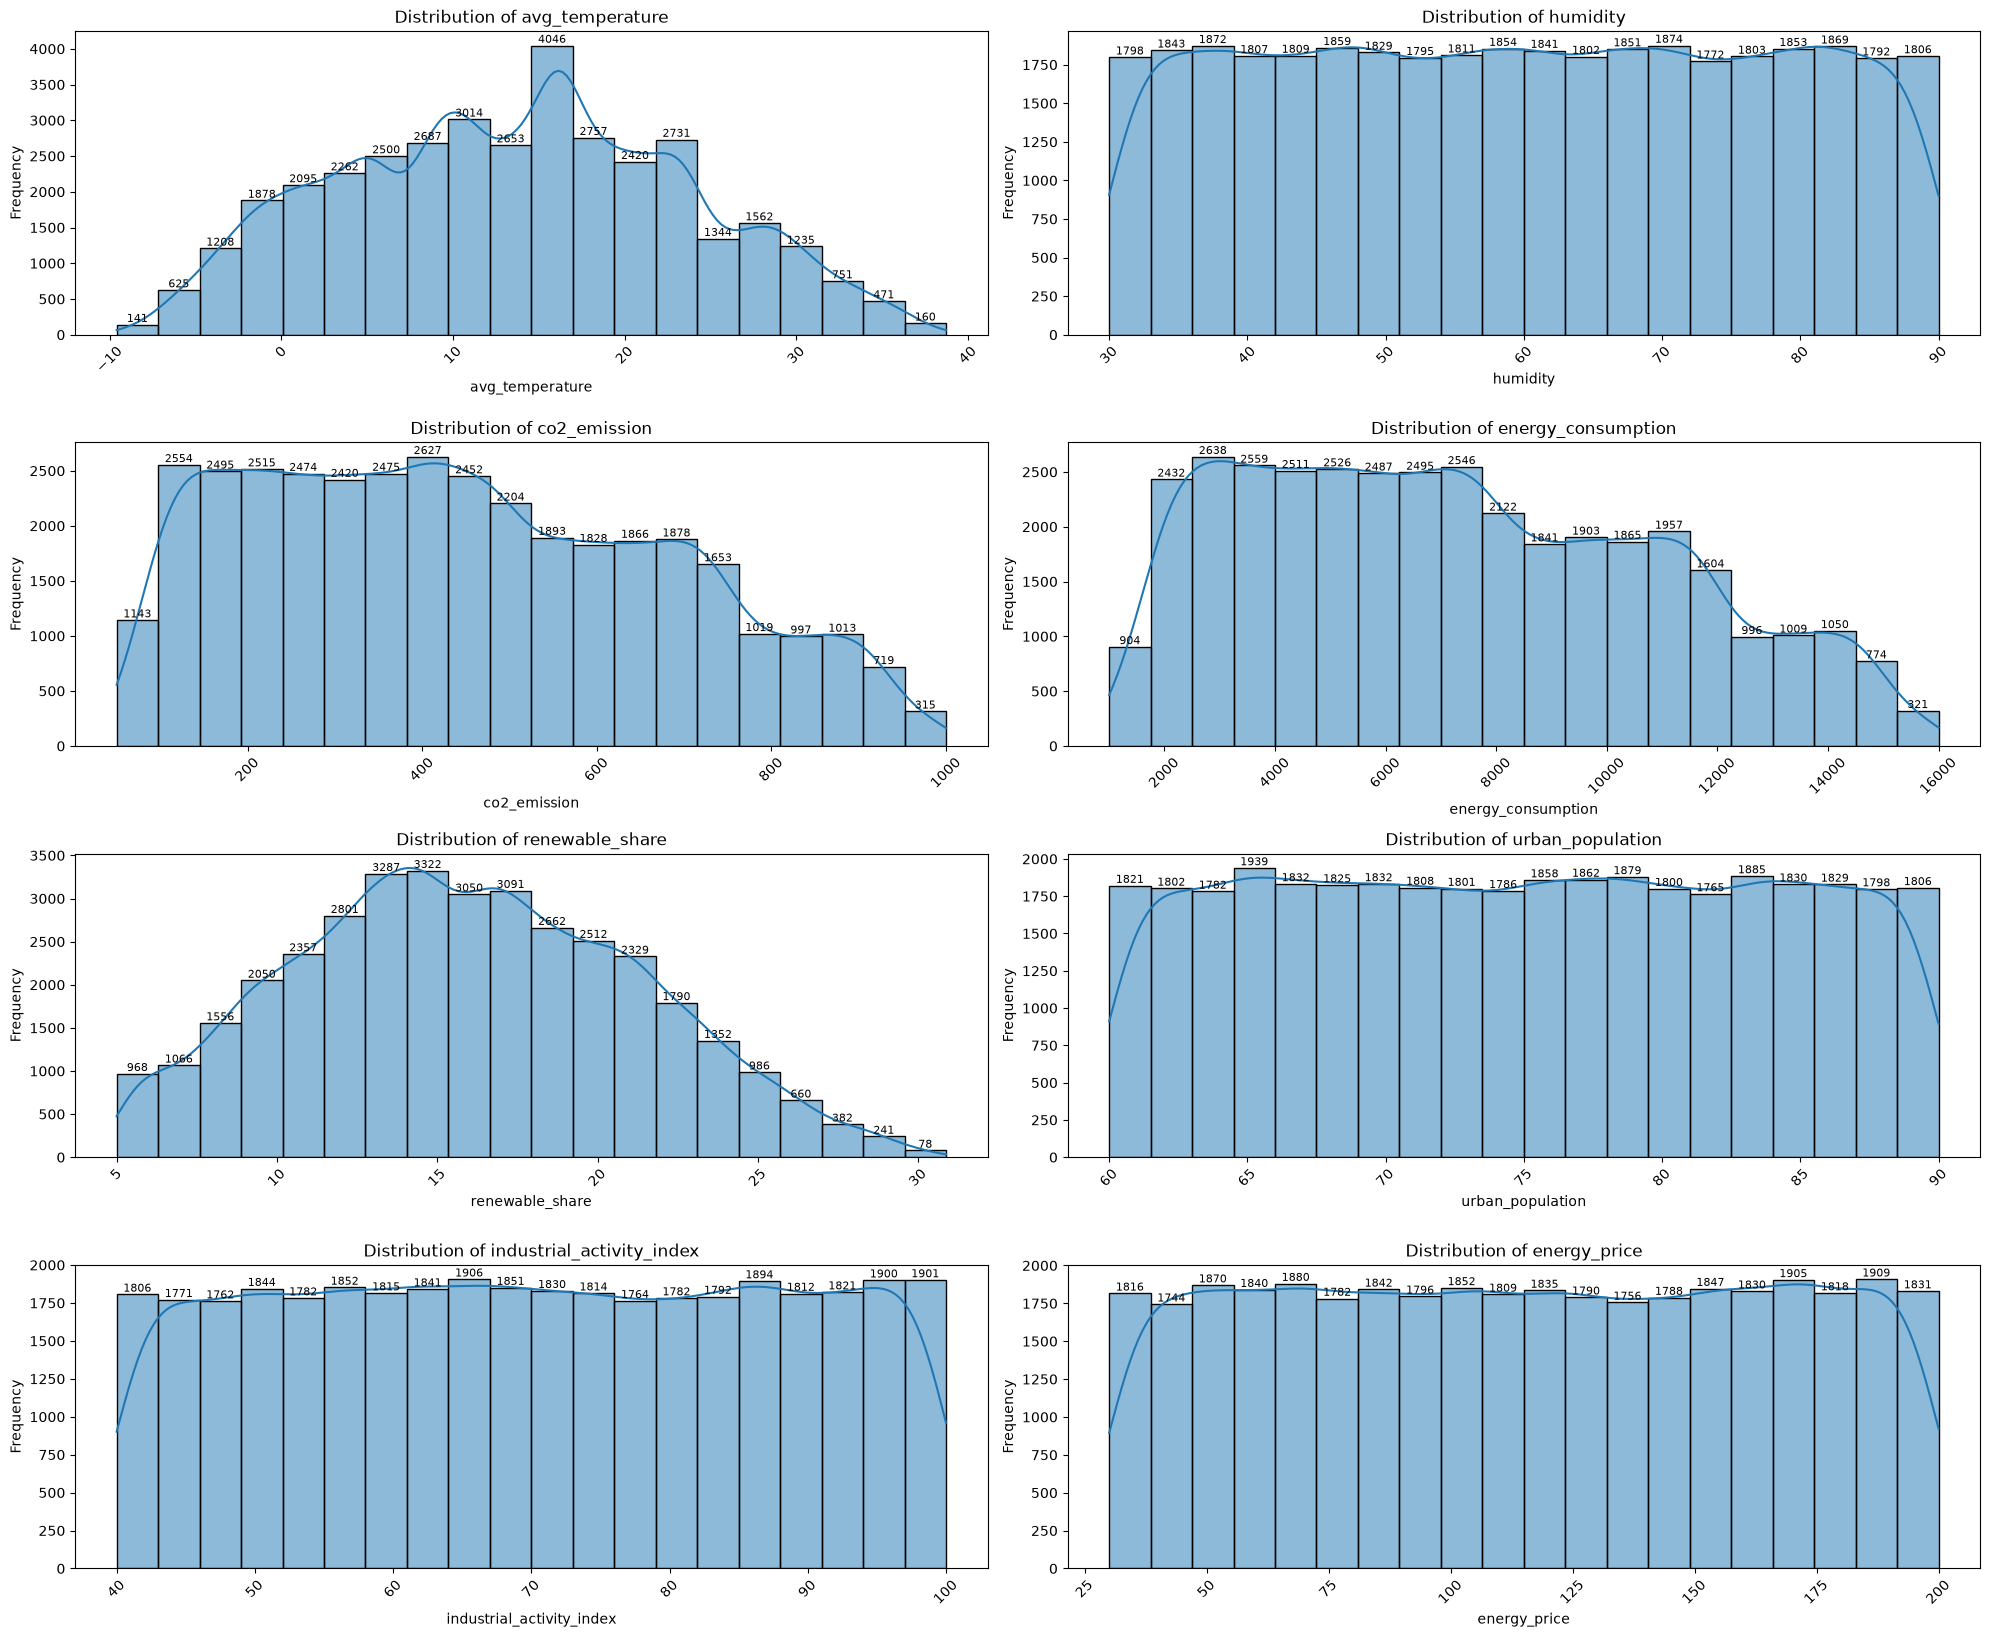

In [20]:
plt.figure(figsize=(20, 20))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(5, 2, i)

    ax = sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Add count labels on each bar
    for p in ax.patches:
        height = p.get_height()
        ax.text(
            p.get_x() + p.get_width()/2,
            height + 0.5,
            int(height),
            ha='center',
            va='bottom',
            fontsize=8
        )

    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
import altair as alt

In [22]:
# Show Average Temperature by country
columns_to_average = ['avg_temperature', 'energy_consumption', 'renewable_share','co2_emission']
country_averages = df.groupby('country')[columns_to_average].mean().reset_index()

chart_temp = alt.Chart(country_averages).mark_bar().encode(
    x=alt.X('avg_temperature:Q', title='Average Temperature'),
    y=alt.Y('country:N', title='Country', sort ='-x'),
    tooltip=[
        alt.Tooltip('country:N', title='Country'),
        alt.Tooltip('avg_temperature:Q', title= 'Avg. Temp', format='.1f')
    ]    
).properties(
    title= 'Average Temperature by Country'
).interactive()

chart_temp.save('barchart_avg_temperature.json')

chart_temp

alt.Chart(...)

In [23]:
# Show average energy consumption by country

chart_energy = alt.Chart(country_averages).mark_bar().encode(
    x=alt.X('energy_consumption:Q', title='Average Energy Consumption'),
    y=alt.Y('country:N', title='Country', sort='-x'),
    tooltip=[
        alt.Tooltip('country:N', title='Country'),
        alt.Tooltip('energy_consumption:Q', title='Avg. Energy', format=',.0f')

    ]
).properties(
    title='Average Energy Consumption by Country'
).interactive()

chart_energy.save('barchart_energy_consumption.json')

chart_energy

alt.Chart(...)

In [24]:
# Create a chart to show Average renewable share

chart_renewable = alt.Chart(country_averages).mark_bar().encode(
    x=alt.X('renewable_share:Q', title='Average Renewable Share (%)'),
    y=alt.Y('country:N', title='Country', sort='-x'),
    tooltip=[
        alt.Tooltip('country:N', title='Country'),
        alt.Tooltip('renewable_share:Q', title='Avg. Share (%)', format='.1f')
    ]
).properties(
    title='Average Renewable Share by Country'
).interactive()

chart_renewable.save('barchart_renewable_share.json')

chart_renewable

alt.Chart(...)

In [25]:
# Average co2 emission chart
chart_co2_avg = alt.Chart(country_averages).mark_bar().encode(
    x=alt.X('co2_emission:Q', title= 'Average CO2 Emissions (Tons/Day)'),
    y=alt.Y('country:N', title='Country', sort='-x'),
    tooltip=[
        alt.Tooltip('country:N', title='Country'),
        alt.Tooltip('co2_emission:Q', title='CO2 Emissions (Tons/Day)', format='.1f')
    ]
).properties(
    title='Average CO2 Emissions by Country'
).interactive()

chart_co2_avg.save('barchart_avg_co2_emissions.json')

chart_co2_avg 

alt.Chart(...)

In [26]:
# Create a pairplot 
columns_of_interest = ['co2_emission', 'urban_population', 'industrial_activity_index',
                       'energy_consumption','humidity','renewable_share',
                       'avg_temperature']
country_average = df.groupby('country')[columns_of_interest].mean().reset_index()


variables = ['co2_emission','urban_population','industrial_activity_index','energy_consumption']

pair_plot = alt.Chart(country_average).mark_circle().encode(
    x=alt.X(alt.repeat("column"), type='quantitative'),
    y=alt.Y(alt.repeat("row"), type='quantitative'),
    tooltip=['country'] + variables
).properties(
    title='Averages by Country',
    width=200,
    height=200
).repeat(
    row=variables,
    column=variables
).interactive()

pair_plot_path = 'correlation_pair_plot.json'
pair_plot.save(pair_plot_path)

pair_plot

alt.RepeatChart(...)

In [27]:
# Show renewable energy share growth
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df.dropna(subset=['date'], inplace=True)
daily_avg_renewable = df.groupby('date')['renewable_share'].mean().reset_index()

chart= alt.Chart(daily_avg_renewable).mark_line().encode(
    x=alt.X('date:T', title='Date'),
    y=alt.Y('renewable_share:Q', title='Avg. Renewable Share (%)'),
    tooltip=[
        alt.Tooltip('date:T', title='Date', format= '%Y-%m-%d'),
        alt.Tooltip('renewable_share:Q', title='Avg. Share (%)', format='.2f')
    ]
).properties(
    title='Global Average Renewable Energy Share (2020-2024)',
    width=600,
    height=300
).interactive()

chart_path = 'global_renewable_share_line.json'
chart.save(chart_path)

chart

alt.Chart(...)

In [30]:
df['country'] = LabelEncoder().fit_transform(df['country'])
df.drop(columns=['date'], inplace=True)

In [31]:
df.head()

,country,avg_temperature,humidity,co2_emission,energy_consumption,renewable_share,urban_population,industrial_activity_index,energy_price
0,5,28.29,31.08,212.63,11348.75,14.42,76.39,51.22,83.93
1,5,28.38,37.94,606.05,4166.64,5.63,86.26,78.27,110.40
2,5,28.74,57.67,268.72,4503.80,14.20,75.92,48.96,173.58
3,5,26.66,51.34,167.32,3259.13,13.84,63.15,97.42,89.13
4,5,26.81,65.38,393.89,7023.72,6.93,76.02,81.89,40.60


In [29]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

In [32]:
y = df['energy_consumption'] ## Target variable 
X = df.drop(columns = ['energy_consumption']) ## dependend variable

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [34]:
scaler = StandardScaler()

In [35]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [36]:
model = LinearRegression()

In [37]:
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [38]:
# Linear Regression
print("1. Linear Regression Model")
print("-" * 40)

print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")

1. Linear Regression Model
----------------------------------------
R2 Score: 0.0304
RMSE: 3653.1292
MAE: 3081.1504


In [39]:
model = RandomForestRegressor()

In [40]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [41]:
y_pred = model.predict(X_test)

In [42]:
# Random Forest Regressor
print("1. Random Forest Regressor")
print("-" * 40)

print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")

1. Random Forest Regressor
----------------------------------------
R2 Score: 0.0997
RMSE: 3520.2074
MAE: 2959.6238
